# Lee（2025）· 因子拥挤度与尾部风险

**原文**：Chorok Lee，*Not All Factors Crowd Equally: Modeling, Measuring, and Trading on Alpha Decay*，arXiv 2512.11913。
整理稿 5.3 节依据的是 QuantML 公众号对该文 v1（2025-12）的中文解读。

**版本说明**：作者于 2026-09 发布了 v3，标题改为 *Return-Decay Residuals and Tail-Risk Forecasting:
Timing Artifacts, Conditional Inference, and Cross-Market Evidence*，自己指出 v1 把「同期残差」当成了预测，
并撤回了双曲线衰减拟合得好的说法。本 notebook **按 v1 的方法独立复现**，再用自己的数据和代码检验 v1 的问题，
不依赖 v3 的结论。

## v1 的做法与结论

| 项 | v1 |
|---|---|
| 数据 | Kenneth French 数据库，8 个美股因子（MKT、SMB、HML、RMW、CMA、Mom、ST_Rev、LT_Rev），月度，1963–2024 |
| alpha 代理 | 滚动 36 个月夏普 |
| 衰减模型 | 双曲线 K/(1+λt)，对比指数、线性；1995–2024 年的**正夏普观测**上拟合（表 2：Mom R² 0.65） |
| 拥挤信号 | 扩展窗口（≥120 个月）拟合双曲线，残差 = 实际 − 预测，负残差 = 拥挤 |
| 尾部检验 | 1980–2000 定阈值：拥挤 = 残差低于训练期中位数，崩盘 = 收益低于训练期 10% 分位；2001–2024 样本外（表 4） |
| 结论 | 拥挤时反转因子崩盘概率是不拥挤时的 1.65–1.84 倍；动量相反，仅 0.38 倍（p=0.006） |

**v1 未说明、本复现的取法**：时间 t 从 1995 年起算（年）；非线性最小二乘；拥挤残差用严格早于当月的数据拟合；
崩盘同时给出「当月」与「下月」两种口径；p 值用 Fisher 精确检验。v1 的交易策略和 ETF 成交量分析没有给出定义，未复现。

## 0 · 环境与数据

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tailrisk").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from tailrisk import data, crowding as cw

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.figsize": (13, 4),
    "axes.unicode_minus": False,
    "font.sans-serif": ["PingFang SC", "Heiti TC", "Arial Unicode MS", "SimHei", "DejaVu Sans"],
})

F = data.load_french_factors()
FACTORS = list(F.columns)
S = {f: cw.rolling_sharpe(F[f], 36) for f in FACTORS}
TRAIN, TEST = ("1980-01-01", "2000-12-31"), ("2001-01-01", "2024-12-31")
print(f"{F.index.min():%Y-%m} ~ {F.index.max():%Y-%m}，{len(F)} 个月")
(F.agg(["mean", "std"]).T * [12, np.sqrt(12)]).rename(columns={"mean": "年化收益", "std": "年化波动"}).style.format("{:.1%}")

1963-07 ~ 2026-08，758 个月


,年化收益,年化波动
Mkt-RF,7.2%,15.4%
SMB,2.2%,10.5%
HML,3.5%,10.3%
RMW,3.0%,7.9%
CMA,2.9%,7.2%
Mom,7.2%,14.6%
ST_Rev,4.7%,11.0%
LT_Rev,2.6%,9.2%


---
# 1 · 衰减曲线的拟合（v1 表 2）

In [2]:
V1_T2 = {"Mom": (0.65, 0.61, 0.51), "LT_Rev": (0.30, 0.29, 0.26), "ST_Rev": (0.15, 0.15, 0.14), "SMB": (0.10, 0.13, 0.17),
         "Mkt-RF": (0.07, 0.07, 0.07), "HML": (0.05, 0.06, 0.07), "RMW": (0.05, 0.05, 0.05), "CMA": (0.01, 0.01, 0.01)}
rows = {}
for f in FACTORS:
    pos = cw.decay_r2(S[f], positive_only=True)
    allobs = cw.decay_r2(S[f], positive_only=False)
    rows[f] = {"v1 双曲线": V1_T2[f][0], "v1 指数": V1_T2[f][1], "v1 线性": V1_T2[f][2],
               "复现 双曲线": pos["双曲线"], "复现 指数": pos["指数"], "复现 线性": pos["线性"],
               "全部观测（含负夏普）双曲线": allobs["双曲线"]}
pd.DataFrame(rows).T.style.format("{:.3f}")

,v1 双曲线,v1 指数,v1 线性,复现 双曲线,复现 指数,复现 线性,全部观测（含负夏普）双曲线
Mkt-RF,0.070,0.070,0.070,0.066,0.065,0.065,-0.000
SMB,0.100,0.130,0.170,0.099,0.129,0.166,0.003
HML,0.050,0.060,0.070,0.042,0.050,0.061,0.099
RMW,0.050,0.050,0.050,0.048,0.046,0.042,0.018
CMA,0.010,0.010,0.010,0.008,0.009,0.010,0.080
Mom,0.650,0.610,0.510,0.638,0.601,0.497,0.513
ST_Rev,0.150,0.150,0.140,0.127,0.127,0.121,0.157
LT_Rev,0.300,0.290,0.260,0.309,0.297,0.260,0.192


**判读**：v1 表 2 的 R² 几乎完全复现（Mom 0.64 对 0.65，LT_Rev 0.31 对 0.30）。但这一结果依赖两点：

- **只用正夏普观测**：改用全部观测后，Mom 的双曲线 R² 从 0.64 降到 0.51。只保留正值，会让一条「从正值向零衰减」的曲线显得更合适。
- **滚动窗口高度重叠**：相邻月份的 36 个月夏普共享 35 个月数据，R² 在这种平滑序列上会被系统性抬高，不能当作独立样本的拟合优度来解读。

---
# 2 · 拥挤与崩盘（v1 表 4）

扩展窗口拟合双曲线、计算残差（约十几秒）。崩盘分「当月」（与残差同一个月）和「下月」两种口径。

In [3]:
RES = {f: cw.crowding_residual(S[f], min_obs=120) for f in FACTORS}
V1_T4 = {"ST_Rev": (1.84, 0.078), "Mkt-RF": (1.68, 0.215), "LT_Rev": (1.65, 0.095),
         "CMA": (1.30, 0.677), "SMB": (1.10, 0.773), "Mom": (0.38, 0.006)}
rows = {}
for f in FACTORS:
    for h, label in [(0, "当月"), (1, "下月")]:
        t = cw.crash_table(F[f], RES[f], horizon=h, train=TRAIN, test=TEST)
        rows[(f, label)] = {"v1 比值": V1_T4.get(f, (np.nan,))[0], "v1 p": V1_T4.get(f, (np.nan, np.nan))[1],
                            "P(崩盘|拥挤)": t["P(崩盘|拥挤)"], "P(崩盘|不拥挤)": t["P(崩盘|不拥挤)"],
                            "比值": t["比值"], "Fisher p": t["Fisher p"],
                            "拥挤月数": t["拥挤月数"], "不拥挤月数": t["不拥挤月数"]}
T4 = pd.DataFrame(rows).T
T4.style.format({"v1 比值": "{:.2f}", "v1 p": "{:.3f}", "P(崩盘|拥挤)": "{:.1%}", "P(崩盘|不拥挤)": "{:.1%}",
                 "比值": "{:.2f}", "Fisher p": "{:.3f}", "拥挤月数": "{:.0f}", "不拥挤月数": "{:.0f}"}, na_rep="—")

**判读**：v1 表 4 的比值与本复现的「下月」口径接近（ST_Rev 1.84 对 1.76，LT_Rev 1.65 对 1.38，Mom 0.38 对 0.17）；
「当月」口径的比值普遍更大（ST_Rev 3.1，MKT 4.6）。v1 没有交代用的是哪个口径，下面分别检验两者。

---
# 3 · 时间错位：纯随机数据也能「预测」当月崩盘

收益独立同分布、没有任何拥挤或衰减，走完全相同的流程（滚动夏普 → 扩展窗口双曲线残差 → 训练期定阈值 → 测试期统计），
重复 200 次。t 月的滚动夏普包含 t 月收益，t 月大跌会同时把残差拉低 —— 若崩盘也看 t 月，比值会被机械地抬高。

In [4]:
null = cw.null_crash_ratios(mu=0.004, sigma=0.035, n_months=len(F), n_sims=200, seed=1)
null.columns = ["当月", "下月"]
null.describe(percentiles=[.05, .5, .95]).T[["mean", "5%", "50%", "95%"]].style.format("{:.2f}")

,mean,5%,50%,95%
当月,1.80,0.90,1.64,3.15
下月,0.97,0.40,0.93,1.66


In [5]:
lo, hi = null["下月"].quantile([.025, .975])
nxt = T4.xs("下月", level=1)
pd.DataFrame({"下月比值": nxt["比值"], "纯随机 95% 区间": f"[{lo:.2f}, {hi:.2f}]",
              "落在区间外": (nxt["比值"] < lo) | (nxt["比值"] > hi)}).style.format({"下月比值": "{:.2f}"})

,下月比值,纯随机 95% 区间,落在区间外
Mkt-RF,2.11,"[0.34, 1.87]",True
SMB,1.90,"[0.34, 1.87]",True
HML,0.88,"[0.34, 1.87]",False
RMW,0.62,"[0.34, 1.87]",False
CMA,1.40,"[0.34, 1.87]",False
Mom,0.17,"[0.34, 1.87]",True
ST_Rev,1.76,"[0.34, 1.87]",False
LT_Rev,1.38,"[0.34, 1.87]",False


**判读**：

- 纯随机数据下，「当月」比值均值约 1.8、中位数约 1.6（v3 给出的理论值为 1.61），「下月」约为 1。当月口径的效应主要是机械的。
- 「下月」比值在纯随机下也很分散，95% 区间约为 [0.34, 1.87]。8 个因子中 5 个落在区间内，
  **包括 v1 着重强调的两个反转因子**（ST_Rev 1.76、LT_Rev 1.38）；超出的是市场（2.11）、中盘（1.90，刚好超出，
  且测试期只有 43 个「拥挤」月），以及动量（0.17，原因见第 4 节）。

---
# 4 · 动量「拥挤反而安全」从何而来

拥挤分界取 1980–2000 年残差的中位数。动量那段时间最强，之后衰减 —— 测试期绝大多数月份会被判为拥挤。

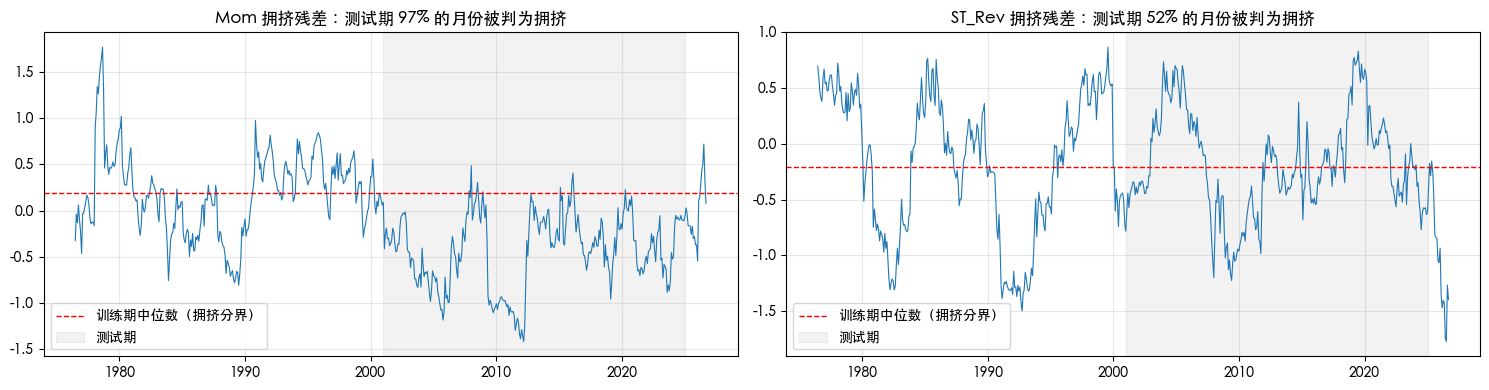

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, f in zip(axes, ["Mom", "ST_Rev"]):
    res = RES[f]
    med = res.loc[TRAIN[0]:TRAIN[1]].median()
    ax.plot(res.index, res, lw=.8)
    ax.axhline(med, color="r", ls="--", lw=1, label="训练期中位数（拥挤分界）")
    ax.axvspan(pd.Timestamp(TEST[0]), pd.Timestamp(TEST[1]), color="gray", alpha=.1, label="测试期")
    share = (res.loc[TEST[0]:TEST[1]] < med).mean()
    ax.set_title(f"{f} 拥挤残差：测试期 {share:.0%} 的月份被判为拥挤"); ax.legend(loc="lower left"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**判读**：动量在测试期 288 个月中有 279 个月被判为「拥挤」，「不拥挤」只有 9 个月。v1 的 0.38 倍（本复现 0.17 倍）
是拿极少数月份算出来的比值，反映的是阈值在样本期之间失效，而不是「动量拥挤是安全信号」。

---
# 5 · 双曲线模型有贡献吗？

把拥挤残差换成最简单的滚动夏普本身（同样以训练期中位数为界，低于为「拥挤」）：

In [7]:
rows = {}
for f in FACTORS:
    a = cw.crash_table(F[f], RES[f], 1, train=TRAIN, test=TEST)
    b = cw.crash_table(F[f], S[f], 1, train=TRAIN, test=TEST)
    rows[f] = {"拥挤残差：下月比值": a["比值"], "滚动夏普：下月比值": b["比值"], "滚动夏普 p": b["Fisher p"]}
pd.DataFrame(rows).T.style.format("{:.2f}")

,拥挤残差：下月比值,滚动夏普：下月比值,滚动夏普 p
Mkt-RF,2.11,2.30,0.01
SMB,1.90,1.29,0.57
HML,0.88,1.14,0.85
RMW,0.62,0.58,0.06
CMA,1.40,1.33,0.64
Mom,0.17,0.13,0.02
ST_Rev,1.76,2.30,0.16
LT_Rev,1.38,1.21,0.61


**判读**：不做任何衰减拟合、直接用滚动夏普，得到的比值与拥挤残差相近甚至更大。衰减模型没有带来额外信息。

---
# 6 · 控制波动率之后还剩什么？

近期夏普低往往伴随近期波动高，而波动率聚集本身就会让下月更容易跌破固定的崩盘线。
把 8 个因子合并做逻辑回归（2001–2024，因子固定效应，按月份聚类标准误），解释变量标准化：

In [8]:
rows = []
for f in FACTORS:
    r = F[f]
    thr = r.loc[TRAIN[0]:TRAIN[1]].quantile(0.10)
    d = pd.DataFrame({"崩盘_当月": (r < thr).astype(float), "崩盘_下月": (r < thr).astype(float).shift(-1),
                      "波动": np.log(r.rolling(12).std()), "残差": RES[f]}).loc[TEST[0]:TEST[1]].dropna()
    for c in ["波动", "残差"]:
        d[c] = (d[c] - d[c].mean()) / d[c].std()
    d["因子"], d["月份"] = f, d.index
    rows.append(d)
D = pd.concat(rows).rename(columns={"崩盘_当月": "crash0", "崩盘_下月": "crash1", "波动": "vol", "残差": "res", "因子": "factor"})
groups = pd.factorize(D["月份"])[0]
out = {}
for y, ylab in [("crash0", "当月崩盘"), ("crash1", "下月崩盘")]:
    for rhs, lab in [("res", "仅残差"), ("vol", "仅波动"), ("vol + res", "波动 + 残差")]:
        m = smf.logit(f"{y} ~ C(factor) + {rhs}", D).fit(disp=0, cov_type="cluster", cov_kwds={"groups": groups})
        out[(ylab, lab)] = {k: f"{m.params[k]:+.3f}（p={m.pvalues[k]:.3f}）" for k in ["res", "vol"] if k in m.params}
pd.DataFrame(out).T.rename(columns={"res": "拥挤残差系数", "vol": "近 12 月波动率系数"}).fillna("")

拥挤残差系数      近 12 月波动率系数
当月崩盘 仅残差      -0.441（p=0.000）                 
     仅波动                       +0.671（p=0.000）
     波动 + 残差  -0.416（p=0.000）  +0.656（p=0.000）
下月崩盘 仅残差      -0.108（p=0.185）                 
     仅波动                       +0.431（p=0.000）
     波动 + 残差  -0.076（p=0.362）  +0.425（p=0.000）

**判读**：对**当月**崩盘，拥挤残差高度显著 —— 这正是第 3 节的时间错位。对**下月**崩盘，拥挤残差单独就不显著，
控制近期波动率后更弱；真正有预测力的是波动率本身（波动率聚集）。

---
# 结论

| 问题 | 结论 |
|---|---|
| v1 表 2（双曲线拟合）能否复现 | **能**，R² 几乎一致；但依赖「只用正夏普观测」，用全部观测后 Mom 从 0.64 降到 0.51，且滚动窗口重叠会抬高 R² |
| v1 表 4（拥挤与崩盘）能否复现 | 比值与本复现的「下月」口径相近；「当月」口径更大 |
| 当月口径 | **时间错位**：纯随机数据下比值均值约 1.8，效应主要是机械的 |
| 下月口径 | 两个反转因子的比值都在纯随机的 95% 区间内，不能与运气区分 |
| 动量 0.38 倍 | **阈值失效**：测试期 288 个月中 279 个月被判为拥挤，比值来自 9 个「不拥挤」月份 |
| 衰减模型是否有贡献 | **没有**：直接用滚动夏普得到相近的比值 |
| 控制波动率后 | 拥挤残差对下月崩盘**没有预测力**；有预测力的是近期波动率 |

这些结论与作者在 v3 中的自我修正一致，由本项目的数据和代码独立得到。